# EN4554 Assignment 2 — Task 2: Optimizers

**Name:** _your name_  **Index number:** _your index_

**GitHub:** https://github.com/chamudiR/EN4554-Assignment-2-on-CNNs

<a href="https://colab.research.google.com/github/chamudiR/EN4554-Assignment-2-on-CNNs/blob/main/Task2_Optimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Use of AI tools:** Claude (Anthropic) was used to help write the code in this notebook. I have gone through and understood all of it.

**Runtime:** Colab T4 GPU (*Runtime → Change runtime type → T4 GPU*). Most of the time goes to the 9 CNN training runs in 2(c), roughly 15–25 minutes in total.

## 0. Setup

This uses the same data pipeline as Task 1, so the same seed gives the identical split:

* Fixed random seeds.
* **45 000 train / 5 000 validation** split of the CIFAR-10 training set.
* Per-channel normalisation with statistics from the **training split only**.
* The **test set is not loaded**. It is used only once, in Task 4.

The images are kept as `(N, 3, 32, 32)` tensors on the GPU, which avoids `DataLoader` overhead. No augmentation is used in this task.

In [ ]:
import copy, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4


In [ ]:
# ---- Load CIFAR-10 training set and make the 45k / 5k split (identical to Task 1) ----
train_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)

X_all = torch.from_numpy(train_full.data).float().div(255).permute(0, 3, 1, 2)  # (50000, 3, 32, 32) in [0, 1]
y_all = torch.tensor(train_full.targets, dtype=torch.long)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

# ---- Per-channel normalisation with TRAINING statistics only ----
mean = X_train.mean(dim=(0, 2, 3))
std  = X_train.std(dim=(0, 2, 3))
X_train = (X_train - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)
X_val   = (X_val   - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)

# ---- GPU copies for training ----
Xtr, ytr = X_train.to(device), y_train.to(device)
Xva, yva = X_val.to(device),   y_val.to(device)

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean (train):', mean.numpy().round(4), '| channel std (train):', std.numpy().round(4))

100%|██████████| 170M/170M [32:39<00:00, 87.0kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean (train): [0.4917 0.4823 0.4467] | channel std (train): [0.2471 0.2435 0.2616]


## Task 2(a): SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

Let $g_t = \nabla_\theta L(\theta_{t-1})$ be the gradient at step $t$.

**SGD with momentum** (heavy ball, in the same form as `torch.optim.SGD` without dampening):

$$
v_t = \mu\, v_{t-1} + g_t \quad (v_1 = g_1), \qquad \theta_t = \theta_{t-1} - \eta\, v_t .
$$

With $\mu = 0$ this is plain SGD. The velocity $v_t$ is a running sum of past gradients. Along a direction where the gradient keeps the same sign it grows towards $g/(1-\mu)$, so the effective step size is $\eta/(1-\mu)$, which is $10\eta$ for $\mu = 0.9$.

**Adam** (Kingma & Ba, 2015):

$$
m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2, \qquad m_0 = v_0 = 0
$$
$$
\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}, \qquad
\theta_t = \theta_{t-1} - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$

**Bias correction.** Because $m_0 = v_0 = 0$, the raw averages are biased towards zero in early steps. At $t = 1$, $m_1 = 0.1\,g_1$ and $v_1 = 0.001\,g_1^2$. Without correction the first step would be $\eta \cdot 0.1 g_1 / (0.0316 |g_1|) \approx 3.2\,\eta$ in each coordinate. Dividing by $1-\beta^t$ removes this bias exactly when the gradient is constant. The first step then becomes $\eta\,\mathrm{sign}(g_1)$, and the correction fades as $t$ grows.

Both classes keep their per-parameter state (`momentum_buffer`, or `step`, `exp_avg`, `exp_avg_sq`) in `self.state[p]`, as PyTorch's own optimizers do. They therefore work with any model and with `zero_grad()`.

In [ ]:
class MySGD(torch.optim.Optimizer):
    # SGD with optional (heavy-ball) momentum.
    def __init__(self, params, lr, momentum=0.0):
        if lr <= 0 or momentum < 0:
            raise ValueError('invalid lr or momentum')
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu = group['lr'], group['momentum']
            for p in group['params']:
                if p.grad is None:
                    continue
                d = p.grad
                if mu != 0:
                    state = self.state[p]
                    if 'momentum_buffer' not in state:            # first step: v_1 = g_1
                        state['momentum_buffer'] = d.clone()
                    else:                                          # v_t = mu * v_{t-1} + g_t
                        state['momentum_buffer'].mul_(mu).add_(d)
                    d = state['momentum_buffer']
                p.add_(d, alpha=-lr)                               # theta <- theta - lr * v_t
        return loss


class MyAdam(torch.optim.Optimizer):
    # Adam with bias correction.
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        if lr <= 0 or not (0 <= betas[0] < 1 and 0 <= betas[1] < 1):
            raise ValueError('invalid lr or betas')
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps = group['lr'], group['betas'], group['eps']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)        # m
                    state['exp_avg_sq'] = torch.zeros_like(p)     # v
                state['step'] += 1
                t, m, v = state['step'], state['exp_avg'], state['exp_avg_sq']

                m.mul_(b1).add_(g, alpha=1 - b1)                   # m_t = b1 m + (1-b1) g
                v.mul_(b2).addcmul_(g, g, value=1 - b2)            # v_t = b2 v + (1-b2) g^2
                m_hat = m / (1 - b1 ** t)                          # bias correction
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

### Verifying against `torch.optim.SGD` and `torch.optim.Adam`

Two identical copies of a small CNN are made with `copy.deepcopy`, so they have the same initial weights. One copy is trained with my optimizer and the other with PyTorch's, for 200 steps on the same sequence of mini-batches of CIFAR-10 images. After every step the largest absolute difference between corresponding parameters is recorded. At the end `torch.allclose` is applied to every parameter tensor.

This runs in **float64** on the CPU, so the comparison is not affected by float32 round-off or non-deterministic GPU kernels. Three settings are checked: plain SGD, SGD with momentum 0.9, and Adam with default betas.

                    optimizer max |θ_mine − θ_torch| (any step)  torch.allclose (all params) final loss (mine) final loss (torch)
                SGD (lr=0.05)                          0.00e+00                         True      1.2220893484       1.2220893484
SGD + momentum (lr=0.05, 0.9)                          0.00e+00                         True      0.7759864043       0.7759864043
               Adam (lr=1e-3)                          1.53e-16                         True      1.0707127884       1.0707127884


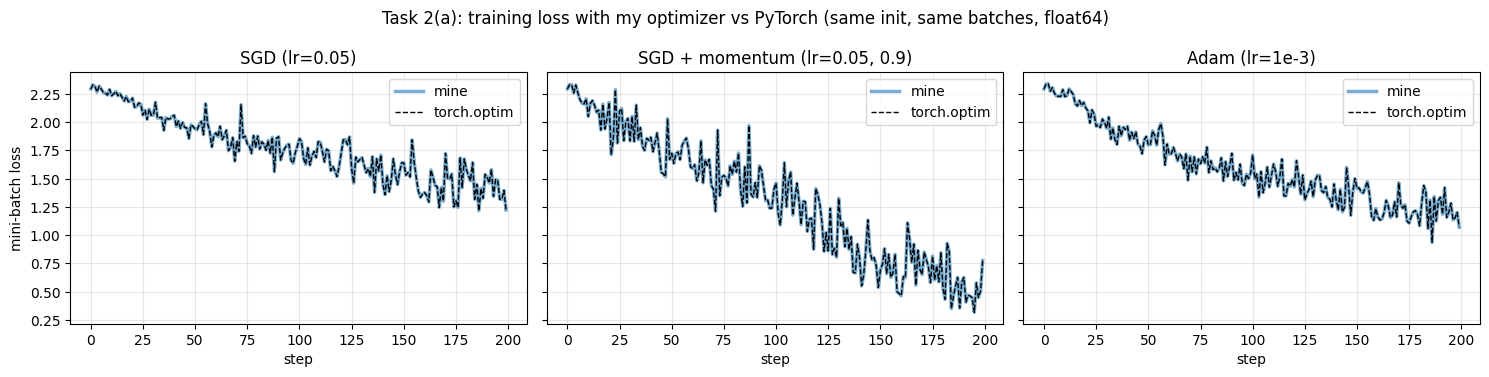

In [ ]:
def tiny_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(16 * 8 * 8, 10))


def compare_optimizers(make_mine, make_ref, steps=200, batch=64):
    set_seed(0)
    model_mine = tiny_cnn().double()
    model_ref = copy.deepcopy(model_mine)                 # identical starting weights
    opt_mine, opt_ref = make_mine(model_mine.parameters()), make_ref(model_ref.parameters())
    X, y = X_train[:1024].double(), y_train[:1024]
    gen = torch.Generator().manual_seed(0)
    loss_mine, loss_ref, max_diff = [], [], []
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch,), generator=gen)   # same mini-batch for both models
        for model, opt, log in ((model_mine, opt_mine, loss_mine), (model_ref, opt_ref, loss_ref)):
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            log.append(loss.item())
        max_diff.append(max((a - b).abs().max().item()
                            for a, b in zip(model_mine.parameters(), model_ref.parameters())))
    all_close = all(torch.allclose(a, b) for a, b in zip(model_mine.parameters(), model_ref.parameters()))
    return dict(loss_mine=loss_mine, loss_ref=loss_ref, max_diff=max_diff, all_close=all_close)


checks = {
    'SGD (lr=0.05)':                 (lambda p: MySGD(p, lr=0.05),               lambda p: torch.optim.SGD(p, lr=0.05)),
    'SGD + momentum (lr=0.05, 0.9)': (lambda p: MySGD(p, lr=0.05, momentum=0.9), lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
    'Adam (lr=1e-3)':                (lambda p: MyAdam(p, lr=1e-3),              lambda p: torch.optim.Adam(p, lr=1e-3)),
}
check_res = {name: compare_optimizers(*pair) for name, pair in checks.items()}

print(pd.DataFrame([{'optimizer': name,
                     'max |θ_mine − θ_torch| (any step)': f'{max(r["max_diff"]):.2e}',
                     'torch.allclose (all params)': r['all_close'],
                     'final loss (mine)': f'{r["loss_mine"][-1]:.10f}',
                     'final loss (torch)': f'{r["loss_ref"][-1]:.10f}'}
                    for name, r in check_res.items()]).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, (name, r) in zip(ax, check_res.items()):
    a.plot(r['loss_mine'], lw=2.5, alpha=0.6, label='mine')
    a.plot(r['loss_ref'], 'k--', lw=1, label='torch.optim')
    a.set_title(name); a.set_xlabel('step'); a.grid(alpha=0.3); a.legend()
ax[0].set_ylabel('mini-batch loss')
fig.suptitle('Task 2(a): training loss with my optimizer vs PyTorch (same init, same batches, float64)')
plt.tight_layout(); plt.show()

**Interpretation.**

* **My optimizers reproduce PyTorch's to within float64 round-off.** After 200 steps on identical mini-batches from identical initial weights:
  * **SGD and SGD + momentum:** the largest parameter difference at *any* step is **exactly 0**. The two models are bit-for-bit identical throughout training.
  * **Adam:** the largest difference is **$1.5\times10^{-16}$**, a single unit of float64 round-off.
  * **Overall:** the final losses agree to all 10 printed decimals (1.2220893484, 0.7759864043 and 1.0707127884), `torch.allclose` is `True` for every parameter tensor, and the two loss curves lie exactly on top of each other.
* **Why SGD is bit-identical.** My `MySGD` performs the same floating-point operations in the same order as `torch.optim.SGD`:
  * the first momentum step sets `buf = g.clone()`;
  * later steps compute `buf.mul_(mu).add_(g)`;
  * then `p.add_(buf, alpha=-lr)` updates the parameter.
* **Why Adam differs in the 16th digit.** PyTorch rearranges the update as $\theta \leftarrow \theta - \frac{\eta}{1-\beta_1^t}\, m_t \big/ \big(\sqrt{v_t}/\sqrt{1-\beta_2^t} + \epsilon\big)$. This is algebraically identical to my $\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$, but the different order of operations rounds differently in the last bit.
* **What this verifies.** Training is a nonlinear, chaotic process that amplifies any discrepancy: different weights produce different gradients at the next step. A wrong bias-correction exponent, a different momentum initialisation such as $v_1 = (1-\mu)g_1$, or $\epsilon$ placed inside the square root would make the curves separate visibly within a few steps. Agreement to round-off after 200 steps therefore confirms the update rules, the state initialisation and the bias correction.
* **Side observation.** The three panels use different effective step sizes, so this is not a fair comparison of the optimizers; Task 2(c) makes that comparison. Still, momentum at lr 0.05 (effective step $0.05/(1-0.9) = 0.5$) reaches the lowest loss after 200 steps (0.78, against 1.22 for SGD and 1.07 for Adam).

## Task 2(b): Trajectories on an ill-conditioned quadratic

$$
f(x, y) = \tfrac12 \left(x^2 + 50 y^2\right), \qquad \nabla f = (x,\ 50y), \qquad H = \mathrm{diag}(1, 50).
$$

The minimum is at $(0, 0)$. The curvature is 50 times larger along $y$ than along $x$, so the condition number is $\kappa = 50$ and the contours are long, narrow ellipses.

**Gradient descent on this function, analytically.** Each coordinate evolves independently:

$$
x_{k+1} = (1-\eta)\,x_k, \qquad y_{k+1} = (1-50\eta)\,y_k .
$$

Gradient descent is stable only if $|1-50\eta| < 1$, that is $\eta < 2/50 = 0.04$. The steep $y$ direction sets the largest usable learning rate, and the flat $x$ direction then makes progress at only $(1-\eta)$ per step.

**Settings.** All three optimizers start at $(-10, 1)$ and run for 100 steps. They use my implementations from 2(a), with autograd computing $\nabla f$.

* **SGD:** $\eta = 0.035$, close to the stability limit.
* **SGD with momentum:** the same $\eta = 0.035$, with $\mu = 0.9$.
* **Adam:** $\eta = 0.3$, with default betas. Adam's step size is in parameter units rather than gradient units, so its $\eta$ is not comparable to SGD's.

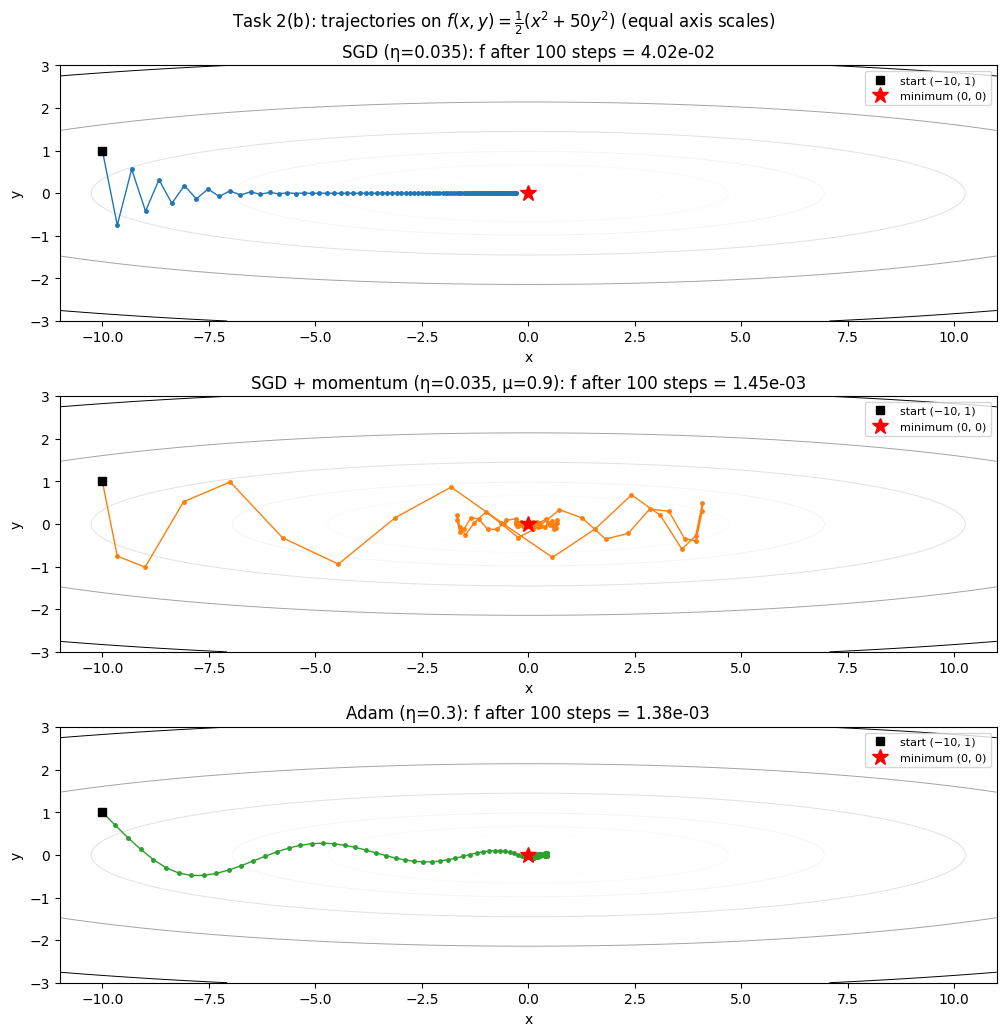

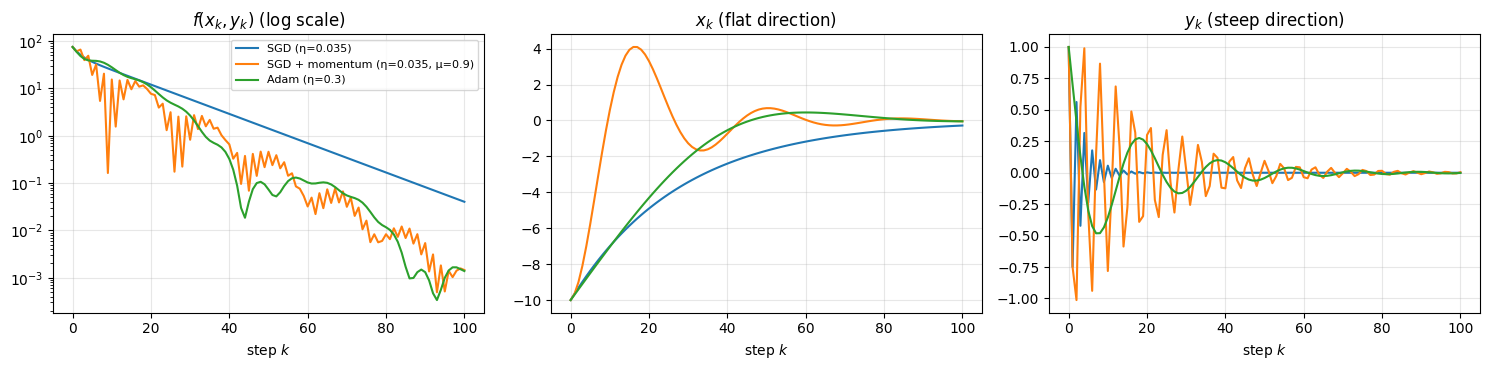

                   SGD (η=0.035): final (x, y) = (-0.2836,  0.0000),  f = 4.022e-02
 SGD + momentum (η=0.035, μ=0.9): final (x, y) = (-0.0451,  0.0042),  f = 1.452e-03
                    Adam (η=0.3): final (x, y) = (-0.0513, -0.0016),  f = 1.384e-03


In [ ]:
def f2d(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


def run_2d(make_opt, start=(-10.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path, vals = [p.detach().clone()], [f2d(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        f2d(p).backward()
        opt.step()
        path.append(p.detach().clone())
        vals.append(f2d(p).item())
    return torch.stack(path).numpy(), np.array(vals)


LR_SGD, MU, LR_ADAM = 0.035, 0.9, 0.3
runs_2d = {
    f'SGD (η={LR_SGD})':                   run_2d(lambda ps: MySGD(ps, lr=LR_SGD)),
    f'SGD + momentum (η={LR_SGD}, μ={MU})': run_2d(lambda ps: MySGD(ps, lr=LR_SGD, momentum=MU)),
    f'Adam (η={LR_ADAM})':                  run_2d(lambda ps: MyAdam(ps, lr=LR_ADAM)),
}
colors_2d = ['C0', 'C1', 'C2']

gx, gy = np.meshgrid(np.linspace(-11, 11, 500), np.linspace(-3, 3, 300))
gz = 0.5 * (gx ** 2 + 50 * gy ** 2)
levels = np.logspace(-2, np.log10(250), 14)

fig, axes = plt.subplots(3, 1, figsize=(11, 10.5))
for ax, (name, (path, vals)), c in zip(axes, runs_2d.items(), colors_2d):
    ax.contour(gx, gy, gz, levels=levels, cmap='Greys', linewidths=0.7)
    ax.plot(path[:, 0], path[:, 1], 'o-', color=c, ms=2.5, lw=1)
    ax.plot(*path[0], 'ks', ms=6, label='start (−10, 1)')
    ax.plot(0, 0, 'r*', ms=12, label='minimum (0, 0)')
    ax.set_aspect('equal'); ax.set_xlim(-11, 11); ax.set_ylim(-3, 3)
    ax.set_title(f'{name}: f after 100 steps = {vals[-1]:.2e}')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(loc='upper right', fontsize=8)
fig.suptitle(r'Task 2(b): trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$ (equal axis scales)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for (name, (path, vals)), c in zip(runs_2d.items(), colors_2d):
    ax[0].semilogy(vals, color=c, label=name)
    ax[1].plot(path[:, 0], color=c, label=name)
    ax[2].plot(path[:, 1], color=c, label=name)
for a, t in zip(ax, ['$f(x_k, y_k)$ (log scale)', '$x_k$ (flat direction)', '$y_k$ (steep direction)']):
    a.set_title(t); a.set_xlabel('step $k$'); a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

for name, (path, vals) in runs_2d.items():
    print(f'{name:>32}: final (x, y) = ({path[-1, 0]: .4f}, {path[-1, 1]: .4f}),  f = {vals[-1]:.3e}')

**Interpretation.**

| optimizer | final $(x, y)$ after 100 steps | $f$ after 100 steps |
|---|---|---|
| SGD ($\eta = 0.035$) | $(-0.284,\ 0.000)$ | $4.0\times10^{-2}$ |
| SGD + momentum ($\eta = 0.035$, $\mu = 0.9$) | $(-0.045,\ 0.004)$ | $1.5\times10^{-3}$ |
| Adam ($\eta = 0.3$) | $(-0.051,\ -0.002)$ | $1.4\times10^{-3}$ |

* **SGD: fast zig-zag in $y$, slow crawl in $x$, exactly as the analysis predicts.**
  * **First step:** the gradient at $(-10, 1)$ is $(-10, 50)$, which points almost straight up the steep valley wall. The step $-\eta\nabla f = (0.35, -1.75)$ overshoots $y$ to $-0.75$.
  * **The $y$ zig-zag:** $y$ is then multiplied by $1 - 50\eta = -0.75$ every step. The path zig-zags across the valley, and the oscillation dies out within about 10 steps ($0.75^{10} \approx 0.06$).
  * **The slow $x$ direction:** $x$ shrinks by only $1 - \eta = 0.965$ per step. The predicted final value $-10 \times 0.965^{100} = -0.284$ matches the measured $x = -0.2836$.
  * **Straight line on the log plot:** once $y$ has decayed, $f \approx \tfrac12 x^2$ falls by $0.965^2$ per step, which is a straight line on the log plot.
  * **Why the learning rate cannot be raised:** the steep direction diverges for $\eta > 2/50 = 0.04$. The flat direction is therefore stuck with a slow rate, set by the condition number $\kappa = 50$.
* **SGD + momentum: 28× lower $f$, but it oscillates in both directions.**
  * **Theory:** with $\mu = 0.9$ and this $\eta$, the iteration's characteristic roots are complex with $|z| = \sqrt{\mu} = 0.949$ in *both* coordinates. Both directions therefore contract at the same rate, and both oscillate.
  * **Along $x$ (the bottleneck):** 0.949 per step is faster than SGD's 0.965. Over 100 steps that is $0.949^{100}/0.965^{100} \approx 1/5$ in $x$, and hence about $1/27$ in $f \propto x^2$, matching the measured ratio of $f$ values ($4.0\times10^{-2}$ / $1.45\times10^{-3} \approx 28$).
  * **The price is overshoot:** $x$ swings to $+4.1$ at step 17, back to $-1.6$ at step 33, then $+0.7$ at step 50. That is a damped oscillation with a period of about 34 steps, as predicted by the roots' angle of 0.185 rad ($2\pi/0.185 \approx 34$). The amplitude shrinks by about 0.4 every half-period, matching $0.949^{17} = 0.41$.
  * **Along $y$, momentum is *worse* than SGD:**
    * SGD's $y$ zig-zag decays at 0.75 per step and is gone after about 10 steps.
    * With momentum it decays only at 0.949 per step. Its amplitude is still about 0.5 after 20 steps and is small but visible until about step 80. This oscillation is what makes the $f$ curve jagged.
    * Momentum does not "damp" the steep direction here. It trades SGD's fast-$y$ / slow-$x$ behaviour for a medium rate in both directions. This is a large net win, because $x$ was the bottleneck.
  * **$\mu = 0.9$ is more momentum than this problem needs.** The optimal heavy-ball setting for $\kappa = 50$ is $\mu = \big(\frac{\sqrt\kappa-1}{\sqrt\kappa+1}\big)^2 \approx 0.57$, with a matched $\eta$, which would converge at about 0.75 per step without the long oscillations.
* **Adam: no zig-zag, a diagonal start, and roughly constant speed.**
  * **Diagonal start:** Adam's first step is exactly $\eta\,\mathrm{sign}(\nabla f) = (+0.3, -0.3)$. The path therefore starts at 45°, not almost straight down the wall as SGD does. Dividing by $\sqrt{\hat v}$ gives every coordinate a step of about $\eta$ regardless of its curvature, which removes the 50× imbalance between the two directions.
  * **No step-to-step zig-zag:** the momentum term $m_t$ ($\beta_1 = 0.9$) smooths out sign flips. Instead $y$ shows a *slow, smooth* oscillation: it overshoots to $-0.48$ around step 7, then $+0.27$, then $-0.15$, decaying over about 40 steps.
  * **Roughly constant speed:** $x$ advances at about $0.25$ per step at first. It decreases almost linearly rather than exponentially, which is typical of sign-like, normalised steps.
  * **Settling:** $x$ overshoots slightly to $+0.45$ around step 60, and then the slowly decaying $\hat v_t$ ($\beta_2 = 0.999$ remembers the large early gradients) shrinks the steps so the iterate settles.
  * **Result:** the final $f = 1.4\times10^{-3}$ equals momentum's, but along a much smoother path.
* **Summary.**
  * **Plain SGD** is limited by the condition number: the steep direction caps $\eta$ and the flat direction then crawls.
  * **Momentum** speeds up the slow direction by accumulating velocity, at the cost of underdamped oscillation if $\mu$ is too large.
  * **Adam** rescales each coordinate separately, which handles *axis-aligned* ill-conditioning like this one especially well. It would lose much of that advantage if the ellipse were rotated, because per-coordinate scaling cannot undo curvature along a diagonal direction.

## Task 2(c): Learning-rate sensitivity on a small CNN

**Model.** Three conv blocks, each Conv3×3 → ReLU → MaxPool2 with 32, 64 and 128 channels, followed by FC 2048 → 256 → 10. The model has about 620k parameters and **no batch norm**, because batch norm would itself reduce sensitivity to the learning rate. Weights use PyTorch's default initialisation.

**Protocol.**
* Each optimizer is trained at three learning rates, each 10× apart.
* SGD and SGD + momentum share the grid $\{10^{-3}, 10^{-2}, 10^{-1}\}$. Momentum is $\mu = 0.9$.
* Adam uses $\{10^{-4}, 10^{-3}, 10^{-2}\}$, centred on its usual default $10^{-3}$.
* Every run trains for 15 epochs with batch size 128. All runs use **the same initial weights and the same mini-batch order** (same seed), so only the optimizer and the learning rate differ.
* A run is marked *diverged* if its training loss becomes NaN or infinite.
* The **best validation accuracy over the 15 epochs** measures each run.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),   # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 16 -> 8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))   # 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


@torch.no_grad()
def evaluate(model, X, y, batch=1000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), batch):
        out = model(X[i:i + batch])
        loss_sum += F.cross_entropy(out, y[i:i + batch], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + batch]).sum().item()
    return loss_sum / len(X), correct / len(X)


def train_model(model, opt, epochs, batch_size=128, seed=SEED, verbose=False):
    gen = torch.Generator().manual_seed(seed)     # same mini-batch order for every run
    hist = {k: [] for k in ['iter_loss', 'train_loss', 'train_acc', 'val_loss', 'val_acc']}
    hist['diverged'] = False
    n = len(Xtr)
    for ep in range(1, epochs + 1):
        model.train()
        order = torch.randperm(n, generator=gen).to(device)
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device, dtype=torch.long)
        iter_losses = []
        for i in range(0, n, batch_size):
            idx = order[i:i + batch_size]
            xb, yb = Xtr[idx], ytr[idx]
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            loss_sum += loss.detach() * len(idx)
            correct += (out.argmax(1) == yb).sum()
            iter_losses.append(loss.detach())
        hist['iter_loss'] += torch.stack(iter_losses).tolist()
        hist['train_loss'].append(loss_sum.item() / n)
        hist['train_acc'].append(correct.item() / n)
        vl, va = evaluate(model, Xva, yva)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if verbose:
            print(f'  epoch {ep:2d} | train loss {hist["train_loss"][-1]:.4f} acc {hist["train_acc"][-1]:.4f} '
                  f'| val loss {vl:.4f} acc {va:.4f}')
        if not math.isfinite(hist['train_loss'][-1]):
            hist['diverged'] = True
            break
    return hist


print('SmallCNN parameters:', sum(p.numel() for p in SmallCNN().parameters()))

SmallCNN parameters: 620362


In [ ]:
EPOCHS = 15
SWEEP = {
    'SGD':            (lambda ps, lr: MySGD(ps, lr=lr),               [1e-3, 1e-2, 1e-1]),
    'SGD + momentum': (lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9), [1e-3, 1e-2, 1e-1]),
    'Adam':           (lambda ps, lr: MyAdam(ps, lr=lr),              [1e-4, 1e-3, 1e-2]),
}

results = {}
for name, (make_opt, lrs) in SWEEP.items():
    for lr in lrs:
        set_seed(SEED)                          # same initial weights for every run
        model = SmallCNN().to(device)
        opt = make_opt(model.parameters(), lr)
        t0 = time.time()
        h = train_model(model, opt, EPOCHS)
        h['time'] = time.time() - t0
        results[(name, lr)] = h
        status = 'DIVERGED' if h['diverged'] else ''
        print(f'{name:>15} lr={lr:<7g} | best val acc {max(h["val_acc"]) * 100:6.2f}% '
              f'| final train loss {h["train_loss"][-1]:.4f} | {h["time"]:.0f}s {status}')

            SGD lr=0.001   | best val acc  31.14% | final train loss 1.9477 | 33s 
            SGD lr=0.01    | best val acc  61.10% | final train loss 1.0294 | 30s 
            SGD lr=0.1     | best val acc  74.62% | final train loss 0.0805 | 31s 
 SGD + momentum lr=0.001   | best val acc  63.20% | final train loss 1.0027 | 32s 
 SGD + momentum lr=0.01    | best val acc  75.22% | final train loss 0.0947 | 32s 
 SGD + momentum lr=0.1     | best val acc  62.50% | final train loss 1.3901 | 32s 
           Adam lr=0.0001  | best val acc  67.06% | final train loss 0.8677 | 34s 
           Adam lr=0.001   | best val acc  76.02% | final train loss 0.0936 | 34s 
           Adam lr=0.01    | best val acc  10.64% | final train loss 2.3036 | 33s 


,optimizer,lr,best val acc (%),epoch of best,final val acc (%),final train loss,final train acc (%),diverged
0,SGD,0.0010,31.14,15,31.14,1.9477,30.92,False
1,SGD,0.0100,61.10,14,60.66,1.0294,63.85,False
2,SGD,0.1000,74.62,14,74.16,0.0805,97.45,False
3,SGD + momentum,0.0010,63.20,15,63.20,1.0027,64.77,False
4,SGD + momentum,0.0100,75.22,10,74.74,0.0947,96.75,False
5,SGD + momentum,0.1000,62.50,6,54.34,1.3901,56.27,False
6,Adam,0.0001,67.06,15,67.06,0.8677,70.11,False
7,Adam,0.0010,76.02,9,75.16,0.0936,96.68,False
8,Adam,0.0100,10.64,3,10.02,2.3036,10.01,False


best learning rate per optimizer: {'SGD': np.float64(0.1), 'SGD + momentum': np.float64(0.01), 'Adam': np.float64(0.001)}


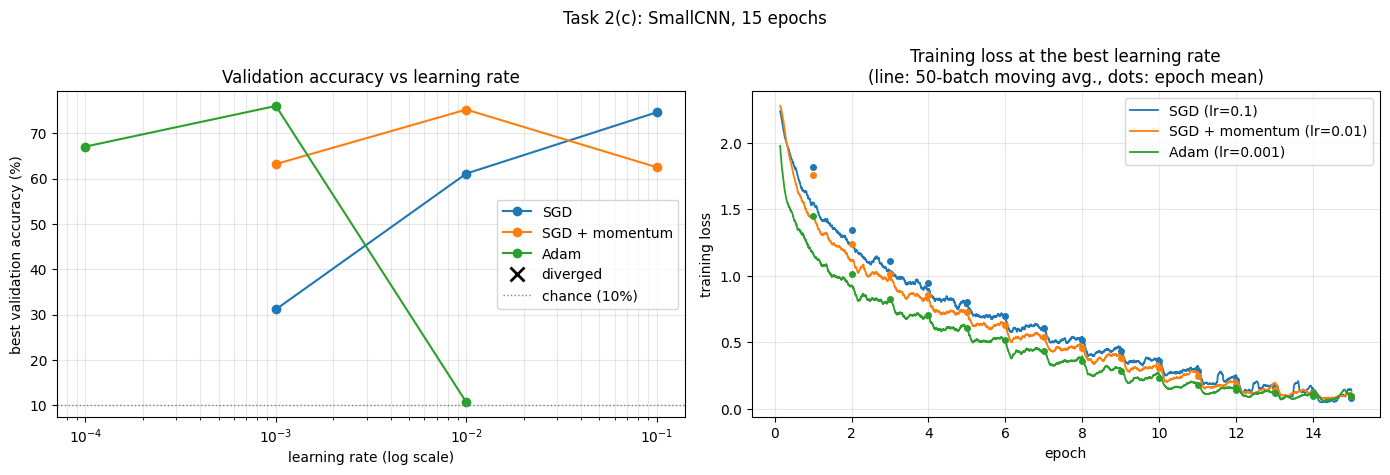

In [ ]:
rows = []
for (name, lr), h in results.items():
    rows.append({'optimizer': name, 'lr': lr,
                 'best val acc (%)': round(max(h['val_acc']) * 100, 2),
                 'epoch of best': int(np.argmax(h['val_acc'])) + 1,
                 'final val acc (%)': round(h['val_acc'][-1] * 100, 2),
                 'final train loss': round(h['train_loss'][-1], 4),
                 'final train acc (%)': round(h['train_acc'][-1] * 100, 2),
                 'diverged': h['diverged']})
table = pd.DataFrame(rows)
display(table)

best_lr = {name: table[table.optimizer == name].sort_values('best val acc (%)').iloc[-1]['lr'] for name in SWEEP}
print('best learning rate per optimizer:', best_lr)

opt_colors = {'SGD': 'C0', 'SGD + momentum': 'C1', 'Adam': 'C2'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for name in SWEEP:
    sub = table[table.optimizer == name]
    ax[0].plot(sub['lr'], sub['best val acc (%)'], 'o-', color=opt_colors[name], label=name)
    div = sub[sub['diverged']]
    ax[0].plot(div['lr'], div['best val acc (%)'], 'x', color='k', ms=10, mew=2)
ax[0].plot([], [], 'kx', ms=10, mew=2, label='diverged')
ax[0].axhline(10, color='grey', ls=':', lw=1, label='chance (10%)')
ax[0].set_xscale('log'); ax[0].set_xlabel('learning rate (log scale)'); ax[0].set_ylabel('best validation accuracy (%)')
ax[0].set_title('Validation accuracy vs learning rate'); ax[0].grid(alpha=0.3, which='both'); ax[0].legend()

for name in SWEEP:
    h = results[(name, best_lr[name])]
    il = np.array(h['iter_loss'])
    k = 50
    sm = np.convolve(il, np.ones(k) / k, mode='valid')
    x_ep = (np.arange(len(sm)) + k) / (len(il) / len(h['train_loss']))
    ax[1].plot(x_ep, sm, color=opt_colors[name], lw=1.3, label=f'{name} (lr={best_lr[name]:g})')
    ax[1].plot(np.arange(1, len(h['train_loss']) + 1), h['train_loss'], 'o', color=opt_colors[name], ms=4)
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss')
ax[1].set_title('Training loss at the best learning rate\n(line: 50-batch moving avg., dots: epoch mean)')
ax[1].grid(alpha=0.3); ax[1].legend()
fig.suptitle('Task 2(c): SmallCNN, 15 epochs')
plt.tight_layout(); plt.show()

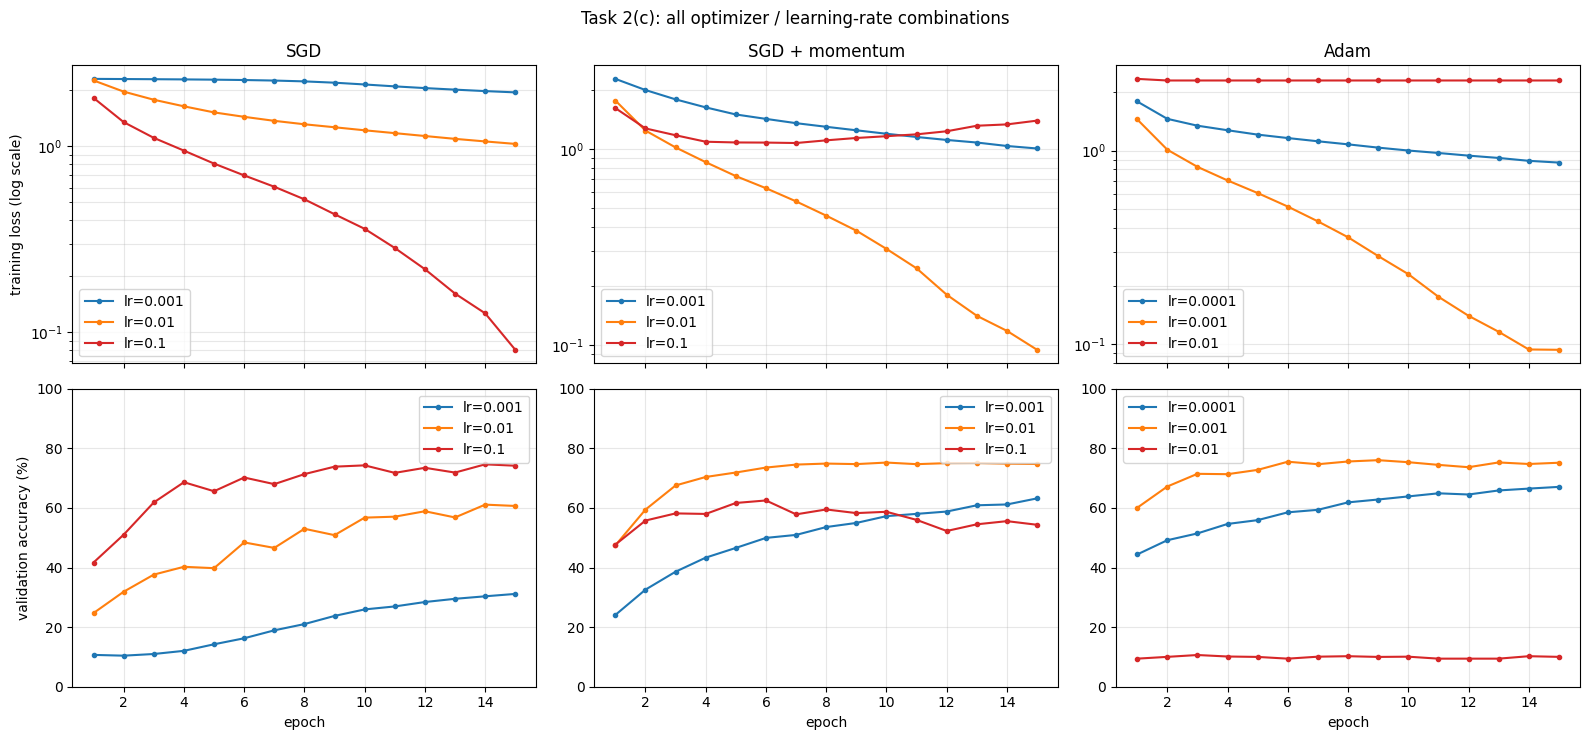

In [ ]:
# All 9 runs: training loss and validation accuracy per epoch, one column per optimizer
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for j, (name, (_, lrs)) in enumerate(SWEEP.items()):
    for lr, c in zip(lrs, ['C0', 'C1', 'C3']):
        h = results[(name, lr)]
        ep = np.arange(1, len(h['train_loss']) + 1)
        label = f'lr={lr:g}' + (' (diverged)' if h['diverged'] else '')
        ax[0, j].plot(ep, h['train_loss'], 'o-', ms=3, color=c, label=label)
        ax[1, j].plot(ep, np.array(h['val_acc']) * 100, 'o-', ms=3, color=c, label=label)
    ax[0, j].set_title(name); ax[0, j].set_yscale('log'); ax[0, j].legend()
    ax[1, j].set_xlabel('epoch'); ax[1, j].set_ylim(0, 100); ax[1, j].legend()
    for a in ax[:, j]:
        a.grid(alpha=0.3, which='both')
ax[0, 0].set_ylabel('training loss (log scale)'); ax[1, 0].set_ylabel('validation accuracy (%)')
fig.suptitle('Task 2(c): all optimizer / learning-rate combinations')
plt.tight_layout(); plt.show()

**Interpretation.**

Best validation accuracy over 15 epochs (%), with the best learning rate of each optimizer in bold:

| optimizer | low lr | middle lr | high lr | spread |
|---|---|---|---|---|
| SGD ($10^{-3}, 10^{-2}, 10^{-1}$) | 31.1 | 61.1 | **74.6** | 43.5 pts |
| SGD + momentum ($10^{-3}, 10^{-2}, 10^{-1}$) | 63.2 | **75.2** | 62.5 | 12.7 pts |
| Adam ($10^{-4}, 10^{-3}, 10^{-2}$) | 67.1 | **76.0** | 10.6 | 65.4 pts |

* **At their best learning rates, the three optimizers are within 1.4 points (74.6 / 75.2 / 76.0%).** The choice of learning rate matters far more than the choice of optimizer. They differ in *speed*: at the best rates, Adam's training loss falls fastest (epoch-1 mean about 1.45, against about 1.75 for momentum and 1.8 for SGD) and stays lowest for most of training. All three reach a training loss of about 0.08–0.09 by epoch 15. All three also overfit: training accuracy is about 97% but validation accuracy about 75%. Validation accuracy stops improving around epochs 9–10 (best epoch 10 for momentum, 9 for Adam) while the training loss keeps falling, because no augmentation or regularisation is used (see Task 3).
* **Plain SGD improves steadily with the learning rate (31 → 61 → 75%).** At $10^{-3}$ the steps are so small that validation accuracy stays near 10% for the first three epochs, while the network sits on the initial plateau. It reaches only 31% after 15 epochs. The best rate, 0.1, is at the edge of the grid, so the true optimum may be at or above 0.1. A wider grid, for example including 0.3, would be needed to locate it.
* **Momentum moves the useful range down by 10×, as predicted by the effective step $\eta/(1-\mu) = 10\eta$.** Momentum at $10^{-3}$ (63.2%, final training loss 1.00) behaves like SGD at $10^{-2}$ (61.1%, 1.03). Momentum at $10^{-2}$ (75.2%, 0.095) behaves like SGD at $10^{-1}$ (74.6%, 0.081). At $10^{-1}$ (effective step 1.0) the step is too large. The loss never becomes NaN, but training is unstable: the training loss stalls near 1.1 and then *rises* from epoch 7 to 1.39. Validation accuracy peaks at 62.5% in epoch 6 and falls to 54%.
* **Adam is best at its default $10^{-3}$, and collapsed at $10^{-2}$.** At $10^{-4}$ it learns but more slowly (67%). At $10^{-2}$ the training loss is 2.3036 from the first epoch onward, essentially $\ln 10 = 2.3026$, and validation accuracy is at chance (10.6%). The run did not produce NaN, so it is not flagged as diverged, but the network *died*.
  * **Why Adam's first steps are so large.** They are about $\eta\,\mathrm{sign}(g)$, a step of 0.01 for *every* weight, regardless of how small its gradient is. PyTorch's default initialisation gives weights of size about $1/\sqrt{\text{fan-in}}$: at most 0.042 for the third conv layer (fan-in 576) and 0.022 for the 2048→256 FC layer. A few such coordinated steps change every weight by a large fraction of its size.
  * **Why the network cannot recover.** The pre-activations shift until the ReLUs output zero for every input. The network's output then no longer depends on the image, and the gradients to all earlier layers are zero. The best the final layer can do is predict the class prior, which gives a loss of exactly $\ln 10$, and nothing can recover the network.
* **Sensitivity is asymmetric.**
  * **Too small a learning rate degrades gracefully.** SGD at $10^{-3}$, Adam at $10^{-4}$ and momentum at $10^{-3}$ all learn steadily and would continue to improve with more epochs.
  * **Too large a learning rate fails abruptly.** Momentum at 0.1 becomes unstable and Adam at 0.01 collapses.
  * **Per-optimizer spread across the grid.** It is largest for Adam (65 points, from best to chance in one decade), then SGD (43 points), and smallest for momentum (13 points), whose grid happened to sit close to its useful range.
  * **Why Adam is still sensitive.** Adam's per-parameter normalisation removes sensitivity to the *scale of the gradients*, but not to $\eta$, because $\eta$ directly sets how far each weight moves per step.
  * **Practical consequence.** Each optimizer has its own useful learning-rate range, so optimizers must be compared at their tuned rates rather than at a shared one.